# ACA N.° 2 – Aprendizaje Automático
## Redes neuronales profundas (MLP y Transformer) para clasificar tumores de mama, con base de datos SQL y despliegue en Streamlit
**Pilar:** Salud · **Dataset:** UCI Breast Cancer Wisconsin (Diagnostic) · **Autor:** Cristian Fernando Marín Caro · **Docente:** Hamilton Rivera Flor · CUN – Especialización en Inteligencia Artificial

**Pregunta orientadora:** ¿cómo aprovechar arquitecturas de redes neuronales para extraer patrones complejos en datos de salud, optimizando el rendimiento predictivo y permitiendo su uso práctico mediante una interfaz en Streamlit?

### Ruta de aprendizaje
| Paso | Qué se hace en este notebook |
|---|---|
| 1. Exploración y gestión SQL | Se guarda el dataset en una base **SQLite** (tablas, restricciones, índices), se consulta con SQL y se explora (EDA) |
| 2. Preparación y pipeline | Partición estratificada registrada en SQL, estandarización, aumento de datos (ruido gaussiano) y pesos de clase |
| 3. Modelado neuronal | **MLP profunda** y **FT-Transformer** (Transformer para datos tabulares), con parada temprana |
| 4. Evaluación | Curvas de pérdida y exactitud, F1, ROC-AUC, matriz de confusión, ajuste del umbral, estabilidad con varias semillas e importancia de variables |
| 5. Despliegue | Exportación de los modelos y artefactos para la app de Streamlit |

### Arquitecturas comparadas
* **MLP profunda:** `Entrada → GaussianNoise → [Dense → BatchNorm → ReLU → Dropout] ×3 (128, 64, 32) → Sigmoide`
* **FT-Transformer** (Gorishniy et al., 2021): cada una de las 30 variables se convierte en un *token* de 32 dimensiones, se antepone un token `[CLS]`, pasan por 2 bloques Transformer (autoatención de 4 cabezas + red feed-forward con conexiones residuales; Vaswani et al., 2017) y la salida del `[CLS]` alimenta un clasificador sigmoide.

> El problema es de **clasificación binaria**: 1 = tumor maligno, 0 = benigno.

## 0. Preparación del entorno

In [1]:
import os, json, sqlite3, time, zipfile, shutil, warnings
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"        # menos mensajes de TensorFlow
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve)
warnings.filterwarnings("ignore")
import logging; logging.getLogger("tensorflow").setLevel(logging.ERROR)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
SEMILLA = 42            # semilla principal (reproducibilidad)
N_SEMILLAS = 5          # repeticiones para medir la estabilidad de cada red

### Módulo `modelos_dl.py` (compartido con la app de Streamlit)
Define las dos redes (capas personalizadas del Transformer incluidas), la estandarización y el entrenamiento. Esta celda lo escribe en disco; en el repositorio es el mismo archivo, de modo que **el notebook y la app usan exactamente la misma arquitectura**.

In [2]:
%%writefile modelos_dl.py
"""
ACA N.° 2 – Aprendizaje Automático (CUN)
Redes neuronales para clasificación de tumores de mama (UCI Breast Cancer Wisconsin – Diagnostic)

Contiene las dos arquitecturas comparadas en el proyecto:
  1) MLP profunda (perceptrón multicapa con normalización por lotes y dropout)
  2) FT-Transformer: Transformer para datos tabulares (Gorishniy et al., 2021): cada variable se convierte en un
     "token", se agrega un token [CLS] y varios bloques de autoatención (Vaswani et al., 2017) los combinan.
Lo usan el notebook (entrenamiento) y la app de Streamlit (inferencia), para que ambos coincidan.
"""
import os

os.environ.setdefault("KERAS_BACKEND", "tensorflow")    # en la app se puede cambiar a "jax" (más liviano)
import json

import keras
import numpy as np
from keras import layers, ops

SEED = 42
BASES = ["radius", "texture", "perimeter", "area", "smoothness", "compactness", "concavity",
         "concave points", "symmetry", "fractal dimension"]
FEATURES = [f"mean {b}" for b in BASES] + [f"{b} error" for b in BASES] + [f"worst {b}" for b in BASES]


# ----------------------------------------------------------------------------- utilidades de datos
def estandarizar(X, media, desv):
    """Z-score con las estadísticas del conjunto de entrenamiento (evita fuga de información)."""
    return ((np.asarray(X, dtype="float32") - np.asarray(media, dtype="float32")) / np.asarray(desv, dtype="float32")).astype("float32")


def pesos_de_clase(y):
    """Pesos inversamente proporcionales a la frecuencia de cada clase (hay ~63 % benignos y ~37 % malignos)."""
    y = np.asarray(y).astype(int)
    n, k = len(y), 2
    return {c: float(n / (k * (y == c).sum())) for c in (0, 1)}


# ----------------------------------------------------------------------------- capas del Transformer tabular
@keras.saving.register_keras_serializable(package="aca2")
class FeatureTokenizer(layers.Layer):
    """Convierte cada variable numérica x_i en un vector (token) de d_model dimensiones: x_i * W_i + b_i."""

    def __init__(self, n_features, d_model, **kwargs):
        super().__init__(**kwargs)
        self.n_features, self.d_model = n_features, d_model

    def build(self, input_shape):
        self.w = self.add_weight(shape=(self.n_features, self.d_model), initializer="glorot_uniform", name="w")
        self.b = self.add_weight(shape=(self.n_features, self.d_model), initializer="zeros", name="b")

    def call(self, x):
        return ops.expand_dims(x, -1) * self.w + self.b

    def get_config(self):
        return {**super().get_config(), "n_features": self.n_features, "d_model": self.d_model}


@keras.saving.register_keras_serializable(package="aca2")
class CLSToken(layers.Layer):
    """Antepone un token [CLS] entrenable; su salida final resume a todas las variables."""

    def __init__(self, d_model, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model

    def build(self, input_shape):
        self.cls = self.add_weight(shape=(1, 1, self.d_model), initializer="glorot_uniform", name="cls")

    def call(self, x):
        return ops.concatenate([ops.zeros_like(x[:, :1, :]) + self.cls, x], axis=1)

    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model}


@keras.saving.register_keras_serializable(package="aca2")
class TomarCLS(layers.Layer):
    def call(self, x):
        return x[:, 0, :]


def bloque_transformer(x, d_model, heads, ff, dropout):
    """Bloque Transformer (pre-normalización): autoatención multi-cabeza + red feed-forward, ambas con conexión residual."""
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.MultiHeadAttention(num_heads=heads, key_dim=d_model // heads, dropout=dropout)(h, h)
    x = layers.Add()([x, h])
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.Dense(ff, activation="gelu")(h)
    h = layers.Dropout(dropout)(h)
    h = layers.Dense(d_model)(h)
    return layers.Add()([x, h])


# ----------------------------------------------------------------------------- arquitecturas
def construir_mlp(n_features=30, unidades=(128, 64, 32), dropout=0.25, ruido=0.1):
    """MLP profunda. GaussianNoise = aumento de datos para datos tabulares (solo activo durante el entrenamiento)."""
    entrada = keras.Input((n_features,), name="variables")
    x = layers.GaussianNoise(ruido)(entrada)
    for u in unidades:
        x = layers.Dense(u, kernel_regularizer=keras.regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(dropout)(x)
    salida = layers.Dense(1, activation="sigmoid", name="prob_maligno")(x)
    return keras.Model(entrada, salida, name="MLP_profunda")


def construir_ft_transformer(n_features=30, d_model=32, heads=4, bloques=2, ff=64, dropout=0.1, ruido=0.1):
    """FT-Transformer: tokenizador de variables + [CLS] + bloques de autoatención + cabeza de clasificación."""
    entrada = keras.Input((n_features,), name="variables")
    x = layers.GaussianNoise(ruido)(entrada)
    x = FeatureTokenizer(n_features, d_model)(x)
    x = CLSToken(d_model)(x)
    for _ in range(bloques):
        x = bloque_transformer(x, d_model, heads, ff, dropout)
    x = TomarCLS()(x)
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    x = layers.Dense(d_model, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    salida = layers.Dense(1, activation="sigmoid", name="prob_maligno")(x)
    return keras.Model(entrada, salida, name="FT_Transformer")


def compilar(modelo, lr=1e-3):
    modelo.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                   metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return modelo


def entrenar(modelo, Xtr, ytr, Xva, yva, epocas=300, paciencia=30, batch=32):
    """Entrena con parada temprana (sobre la pérdida de validación) y reducción de la tasa de aprendizaje."""
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(5, paciencia // 3), min_lr=1e-5)]
    h = modelo.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epocas, batch_size=batch, class_weight=pesos_de_clase(ytr),
                   callbacks=callbacks, verbose=0)
    return {k: [float(v) for v in vals] for k, vals in h.history.items()}


def predecir(modelo, X, batch=256):
    """Probabilidad de malignidad. Se llama al modelo directamente (en lugar de model.predict) porque predict de Keras con el
    backend JAX no es seguro entre hilos, y Streamlit ejecuta cada interacción en un hilo distinto."""
    X = np.asarray(X, dtype="float32")
    salidas = [np.asarray(modelo(X[i:i + batch], training=False)).reshape(-1) for i in range(0, len(X), batch)]
    return np.concatenate(salidas)

Writing modelos_dl.py


In [3]:
import importlib, modelos_dl as dl
importlib.reload(dl)
import keras
print("Keras", keras.__version__, "· backend:", keras.backend.backend())

Keras 3.13.2 · backend: tensorflow


## 1. Paso 1 – Exploración y gestión de datos con SQL
El dataset se almacena en una base **SQLite** (`wdbc.db`). El diseño incluye una clave primaria, una restricción `CHECK` sobre el diagnóstico, índices para consultas eficientes y tablas adicionales para registrar experimentos y predicciones.

In [4]:
def cargar_wdbc():
    ruta = next((p for p in (Path("wdbc.data"), Path("corpus/wdbc.data")) if p.exists()), None)
    if ruta:                                   # archivo original de UCI (sin encabezados)
        df = pd.read_csv(ruta, header=None, names=["paciente_id", "diagnostico"] + dl.FEATURES)
        return df, f"archivo original {ruta}"
    from sklearn.datasets import load_breast_cancer   # copia del mismo dataset incluida en scikit-learn
    d = load_breast_cancer(as_frame=True).frame
    df = d[dl.FEATURES].copy()
    df.insert(0, "diagnostico", np.where(d.target == 0, "M", "B"))
    df.insert(0, "paciente_id", np.arange(1, len(df) + 1))
    return df, "copia del dataset UCI WDBC incluida en scikit-learn"

df_raw, origen = cargar_wdbc()
print(f"Origen: {origen} · {df_raw.shape[0]} casos · {len(dl.FEATURES)} variables · nulos: {int(df_raw.isnull().sum().sum())}")
df_raw.head(3)

Origen: copia del dataset UCI WDBC incluida en scikit-learn · 569 casos · 30 variables · nulos: 0


,paciente_id,diagnostico,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,1,M,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,2,M,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,3,M,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [5]:
DB = "wdbc.db"
if Path(DB).exists():
    os.remove(DB)
COLS = [f.replace(" ", "_") for f in dl.FEATURES]            # nombres válidos como columnas SQL
con = sqlite3.connect(DB)
cur = con.cursor()
cur.executescript(f"""
CREATE TABLE pacientes (
    id INTEGER PRIMARY KEY,                                   -- clave sustituta (los id originales de UCI no son únicos)
    paciente_id INTEGER NOT NULL,
    diagnostico TEXT NOT NULL CHECK (diagnostico IN ('M', 'B')),   -- M = maligno, B = benigno
    particion TEXT NOT NULL DEFAULT 'sin_asignar' CHECK (particion IN ('train', 'val', 'test', 'sin_asignar')),
    {", ".join(f"{c} REAL NOT NULL" for c in COLS)}
);
CREATE INDEX idx_pacientes_diagnostico ON pacientes (diagnostico);
CREATE INDEX idx_pacientes_particion ON pacientes (particion, diagnostico);
CREATE TABLE experimentos (
    id INTEGER PRIMARY KEY AUTOINCREMENT, fecha TEXT NOT NULL, modelo TEXT NOT NULL, particion TEXT NOT NULL, umbral REAL,
    accuracy REAL, precision_ REAL, recall REAL, f1 REAL, roc_auc REAL, loss REAL, parametros INTEGER
);
CREATE TABLE predicciones (
    id INTEGER PRIMARY KEY AUTOINCREMENT, fecha TEXT NOT NULL, modelo TEXT NOT NULL, umbral REAL,
    probabilidad REAL, clase TEXT, entrada TEXT
);
""")
filas = [(i + 1, int(row["paciente_id"]), row["diagnostico"], *[float(row[f]) for f in dl.FEATURES])
         for i, (_, row) in enumerate(df_raw.iterrows())]
cur.executemany(f"INSERT INTO pacientes (id, paciente_id, diagnostico, {', '.join(COLS)}) VALUES ({', '.join('?' * (3 + len(COLS)))})", filas)
con.commit()
print("Filas insertadas:", cur.execute("SELECT COUNT(*) FROM pacientes").fetchone()[0], "· integridad:", cur.execute("PRAGMA integrity_check").fetchone()[0])

Filas insertadas: 569 · integridad: ok


**Consultas SQL de exploración**

In [6]:
q_balance = """
SELECT diagnostico, COUNT(*) AS casos,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM pacientes), 1) AS porcentaje
FROM pacientes GROUP BY diagnostico"""
display(pd.read_sql(q_balance, con))

q_medias = """
SELECT diagnostico,
       ROUND(AVG(mean_radius), 2) AS radio_medio, ROUND(AVG(mean_texture), 2) AS textura_media,
       ROUND(AVG(mean_area), 1) AS area_media, ROUND(AVG(mean_concavity), 3) AS concavidad_media,
       ROUND(AVG(worst_concave_points), 3) AS puntos_concavos_peor
FROM pacientes GROUP BY diagnostico"""
display(pd.read_sql(q_medias, con))

# Plan de ejecución: comprueba que la consulta usa el índice (consulta eficiente)
plan = pd.read_sql("EXPLAIN QUERY PLAN SELECT id, mean_radius FROM pacientes WHERE diagnostico = 'M'", con)
display(plan[["detail"]])

,diagnostico,casos,porcentaje
0,B,357,62.7
1,M,212,37.3


,diagnostico,radio_medio,textura_media,area_media,concavidad_media,puntos_concavos_peor
0,B,12.15,17.91,462.8,0.046,0.074
1,M,17.46,21.60,978.4,0.161,0.182


,detail
0,SEARCH pacientes USING INDEX idx_pacientes_dia...


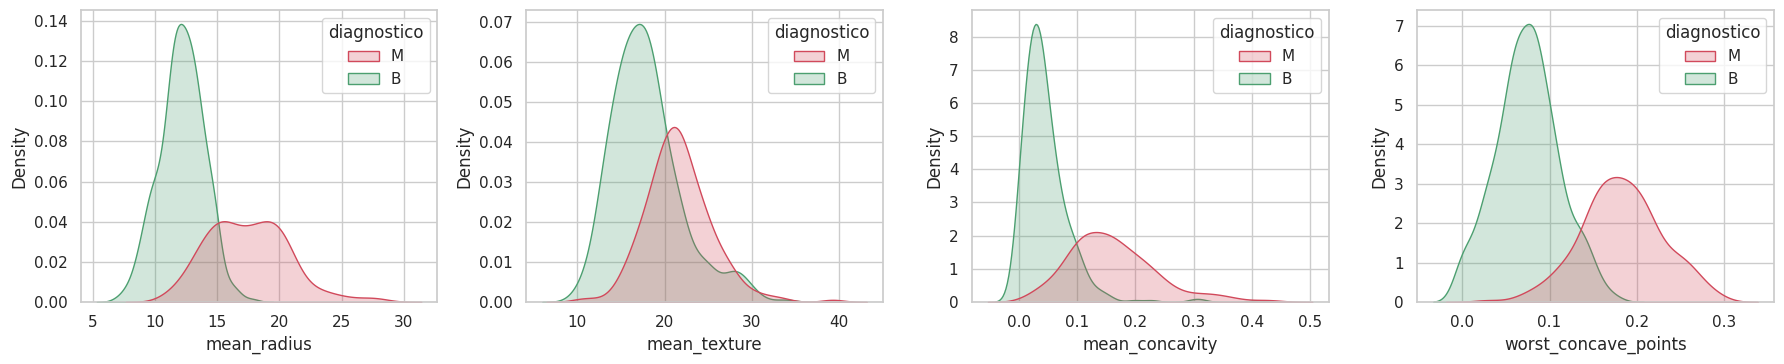

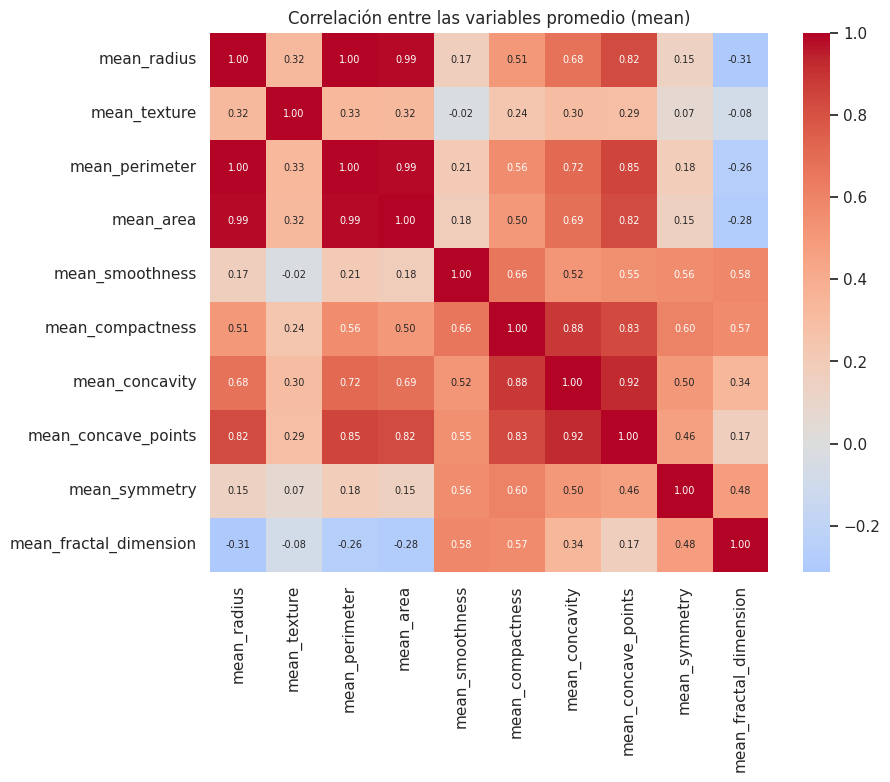

In [7]:
# Análisis exploratorio (datos leídos desde SQL)
eda = pd.read_sql(f"SELECT diagnostico, {', '.join(COLS)} FROM pacientes", con)
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, c in zip(ax, ["mean_radius", "mean_texture", "mean_concavity", "worst_concave_points"]):
    sns.kdeplot(data=eda, x=c, hue="diagnostico", fill=True, ax=a, palette={"B": "#4c9f70", "M": "#d1495b"})
plt.tight_layout(); plt.show()
corr = eda[COLS[:10]].corr()
plt.figure(figsize=(9, 7)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlación entre las variables promedio (mean)"); plt.show()

**Hallazgos:** clases moderadamente desbalanceadas (~63 % benignos / ~37 % malignos); los tumores malignos tienen núcleos más grandes, con más concavidad y puntos cóncavos; radio, perímetro y área están casi perfectamente correlacionados (multicolinealidad), algo que las redes neuronales toleran bien.

## 2. Paso 2 – Preparación de datos y pipeline
* **Partición estratificada 70 / 15 / 15** (entrenamiento / validación / prueba), **registrada en la base SQL** (columna `particion`) para que sea trazable y reproducible. La validación se usa para parar el entrenamiento y elegir el umbral; la prueba solo se usa al final.
* **Estandarización (z-score)** calculada solo con el conjunto de entrenamiento, para evitar fuga de información.
* **Aumento de datos:** capa `GaussianNoise` (ruido gaussiano de 0,1 desviaciones estándar) dentro de las redes; solo actúa durante el entrenamiento y actúa como regularizador que genera variaciones de cada paciente.
* **Desbalance de clases:** pesos de clase inversamente proporcionales a la frecuencia.

In [8]:
ids = pd.read_sql("SELECT id, diagnostico FROM pacientes", con)
tr, tmp = train_test_split(ids, test_size=0.30, stratify=ids.diagnostico, random_state=SEMILLA)
va, te = train_test_split(tmp, test_size=0.50, stratify=tmp.diagnostico, random_state=SEMILLA)
cur.executemany("UPDATE pacientes SET particion = ? WHERE id = ?",
                [("train", int(i)) for i in tr.id] + [("val", int(i)) for i in va.id] + [("test", int(i)) for i in te.id])
con.commit()
display(pd.read_sql("SELECT particion, diagnostico, COUNT(*) AS casos FROM pacientes GROUP BY particion, diagnostico ORDER BY particion", con).pivot(index="particion", columns="diagnostico", values="casos"))

def cargar(particion):
    d = pd.read_sql(f"SELECT id, diagnostico, {', '.join(COLS)} FROM pacientes WHERE particion = ? ORDER BY id", con, params=(particion,))
    return d["id"].values, (d["diagnostico"] == "M").astype(int).values, d[COLS].values
id_tr, ytr, Xtr = cargar("train"); id_va, yva, Xva = cargar("val"); id_te, yte, Xte = cargar("test")
media, desv = Xtr.mean(axis=0), Xtr.std(axis=0)
Ztr, Zva, Zte = (dl.estandarizar(X, media, desv) for X in (Xtr, Xva, Xte))
print("Tamaños:", Ztr.shape, Zva.shape, Zte.shape, "· pesos de clase:", {k: round(v, 3) for k, v in dl.pesos_de_clase(ytr).items()})

diagnostico,B,M
particion,,
test,54,32
train,250,148
val,53,32


Tamaños: (398, 30) (85, 30) (86, 30) · pesos de clase: {0: 0.796, 1: 1.345}


## 3. Paso 3 – Modelado con redes neuronales
Las dos redes se entrenan con **Adam**, pérdida de entropía cruzada binaria, **parada temprana** (paciencia de 30 épocas sobre la pérdida de validación, restaurando los mejores pesos) y reducción de la tasa de aprendizaje cuando la validación se estanca.

In [9]:
CONSTRUCTORES = {"MLP_profunda": dl.construir_mlp, "FT_Transformer": dl.construir_ft_transformer}
modelos, historiales, tiempos = {}, {}, {}
for nombre, build in CONSTRUCTORES.items():
    keras.utils.set_random_seed(SEMILLA)
    m = dl.compilar(build())
    t0 = time.time(); historiales[nombre] = dl.entrenar(m, Ztr, ytr, Zva, yva); tiempos[nombre] = time.time() - t0
    modelos[nombre] = m
    print(f"{nombre:<15} parámetros: {m.count_params():>6,} · épocas: {len(historiales[nombre]['loss']):>3} · tiempo: {tiempos[nombre]:.1f} s")

MLP_profunda    parámetros: 15,233 · épocas:  63 · tiempo: 23.6 s
FT_Transformer  parámetros: 20,193 · épocas:  38 · tiempo: 29.1 s


In [10]:
modelos["MLP_profunda"].summary()

Model: "MLP_profunda"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ variables (InputLayer)          │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise (GaussianNoise)  │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prob_maligno (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,805 (175.02 KB)

 Trainable params: 14,785 (57.75 KB)

 Non-trainable params: 448 (1.75 KB)

 Optimizer params: 29,572 (115.52 KB)

In [11]:
modelos["FT_Transformer"].summary()

Model: "FT_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ variables           │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gaussian_noise_1    │ (None, 30)        │          0 │ variables[0][0]   │
│ (GaussianNoise)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_tokenizer   │ (None, 30, 32)    │      1,920 │ gaussian_noise_1… │
│ (FeatureTokenizer)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cls_token           │ (None, 31, 32)    │         32 │ feature_tokenize… │
│ (CLSToken)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 31, 32)    │         64 │ cls_token[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 31, 32)    │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 31, 32)    │          0 │ cls_token[0][0],  │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 31, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 31, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 31, 64)    │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 31, 32)    │      2,080 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 31, 32)    │          0 │ add[0][0],        │
│                     │                   │            │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 31, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 31, 32)    │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 31, 32)    │          0 │ add_1[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 31, 32)    │         64 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 31, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 31, 64)    │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 60,581 (236.65 KB)

 Trainable params: 20,193 (78.88 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 40,388 (157.77 KB)

**Curvas de aprendizaje** (pérdida y exactitud en entrenamiento y validación):

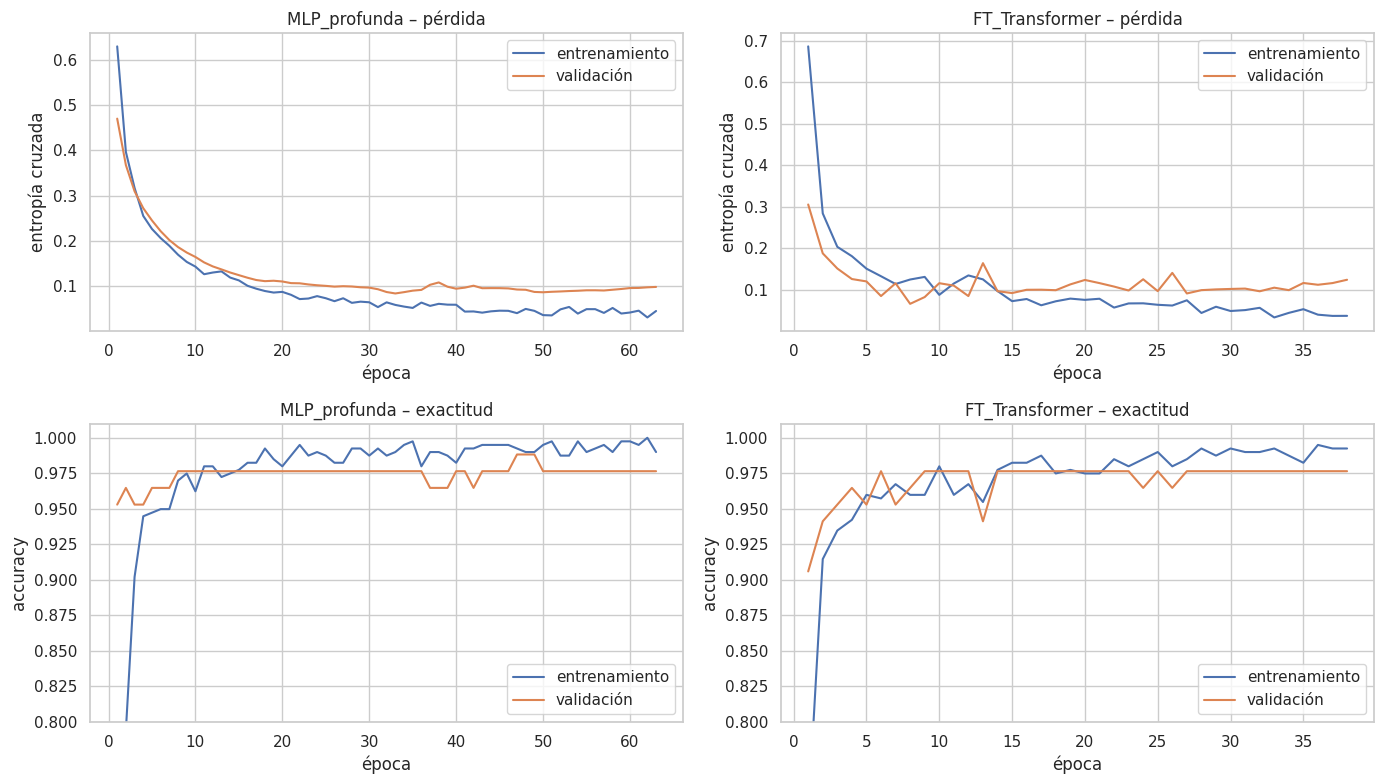

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for j, (nombre, h) in enumerate(historiales.items()):
    ep = range(1, len(h["loss"]) + 1)
    ax[0, j].plot(ep, h["loss"], label="entrenamiento"); ax[0, j].plot(ep, h["val_loss"], label="validación")
    ax[0, j].set(title=f"{nombre} – pérdida", xlabel="época", ylabel="entropía cruzada"); ax[0, j].legend()
    ax[1, j].plot(ep, h["accuracy"], label="entrenamiento"); ax[1, j].plot(ep, h["val_accuracy"], label="validación")
    ax[1, j].set(title=f"{nombre} – exactitud", xlabel="época", ylabel="accuracy", ylim=(0.8, 1.01)); ax[1, j].legend()
plt.tight_layout(); plt.show()

## 4. Paso 4 – Evaluación y métricas
En diagnóstico médico el **recall de la clase maligna** (no dejar escapar tumores malignos) es la métrica prioritaria, junto con F1 y ROC-AUC.

In [13]:
def evaluar(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    p = np.clip(prob, 1e-7, 1 - 1e-7)
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred),
                f1=f1_score(y, pred), roc_auc=roc_auc_score(y, prob),
                loss=float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

prob = {n: {"val": dl.predecir(m, Zva), "test": dl.predecir(m, Zte)} for n, m in modelos.items()}
filas = []
for n in modelos:
    for sp, y in (("val", yva), ("test", yte)):
        filas.append(dict(modelo=n, particion=sp, **evaluar(y, prob[n][sp])))
tabla = pd.DataFrame(filas)
display(tabla[["modelo", "particion", "accuracy", "precision", "recall", "f1", "roc_auc", "loss", "tn", "fp", "fn", "tp"]].round(4))

,modelo,particion,accuracy,precision,recall,f1,roc_auc,loss,tn,fp,fn,tp
0,MLP_profunda,val,0.9765,0.9688,0.9688,0.9688,0.9976,0.0667,52,1,1,31
1,MLP_profunda,test,1.0000,1.0000,1.0000,1.0000,1.0000,0.0242,54,0,0,32
2,FT_Transformer,val,0.9647,0.9677,0.9375,0.9524,0.9976,0.0664,52,1,2,30
3,FT_Transformer,test,0.9884,0.9697,1.0000,0.9846,1.0000,0.0374,53,1,0,32


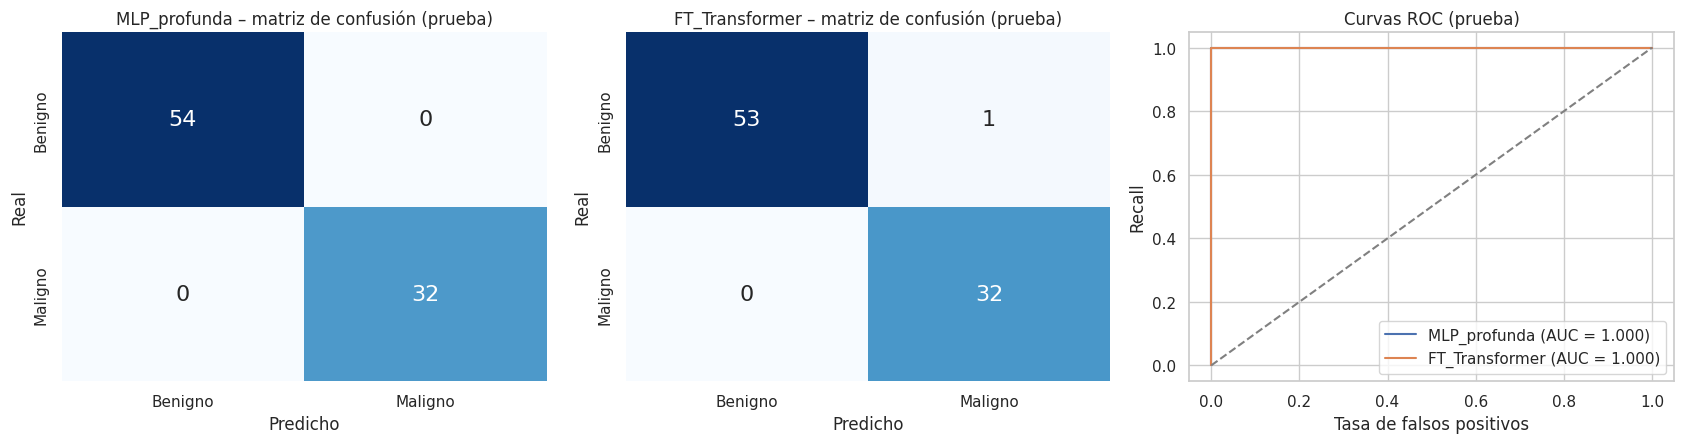

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, n in zip(ax[:2], modelos):
    m = evaluar(yte, prob[n]["test"])
    sns.heatmap([[m["tn"], m["fp"]], [m["fn"], m["tp"]]], annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"], annot_kws={"size": 16})
    a.set(title=f"{n} – matriz de confusión (prueba)", xlabel="Predicho", ylabel="Real")
for n in modelos:
    fpr, tpr, _ = roc_curve(yte, prob[n]["test"]); ax[2].plot(fpr, tpr, label=f"{n} (AUC = {roc_auc_score(yte, prob[n]['test']):.3f})")
ax[2].plot([0, 1], [0, 1], "--", c="gray"); ax[2].set(title="Curvas ROC (prueba)", xlabel="Tasa de falsos positivos", ylabel="Recall"); ax[2].legend()
plt.tight_layout(); plt.show()

### Ajuste del umbral de decisión
El umbral por defecto es 0,5. Para priorizar el recall se elige, **con el conjunto de validación**, el umbral que maximiza el recall manteniendo una precision de al menos 0,95; luego se aplica a prueba.

In [15]:
def umbral_optimo(y, p, prec_min=0.95):
    mejor = None
    for u in np.arange(0.05, 0.96, 0.01):
        m = evaluar(y, p, u)
        if m["precision"] >= prec_min:
            clave = (m["recall"], m["f1"], -abs(u - 0.5))
            if mejor is None or clave > mejor[0]:
                mejor = (clave, round(float(u), 2))
    return mejor[1] if mejor else 0.5

umbrales = {n: umbral_optimo(yva, prob[n]["val"]) for n in modelos}
filas = []
for n in modelos:
    for u, etiqueta in ((0.5, "umbral 0,5"), (umbrales[n], "umbral ajustado")):
        filas.append(dict(modelo=n, umbral=u, criterio=etiqueta, **{k: v for k, v in evaluar(yte, prob[n]["test"], u).items() if k in ("accuracy", "precision", "recall", "f1", "fn", "fp")}))
display(pd.DataFrame(filas).round(4))

,modelo,umbral,criterio,accuracy,precision,recall,f1,fp,fn
0,MLP_profunda,0.50,"umbral 0,5",1.0000,1.0000,1.0,1.0000,0,0
1,MLP_profunda,0.51,umbral ajustado,1.0000,1.0000,1.0,1.0000,0,0
2,FT_Transformer,0.50,"umbral 0,5",0.9884,0.9697,1.0,0.9846,1,0
3,FT_Transformer,0.61,umbral ajustado,1.0000,1.0000,1.0,1.0000,0,0


### Estabilidad: repetición con varias semillas
Con un conjunto de prueba pequeño (86 pacientes) una sola corrida puede ser engañosa. Se entrena cada red con **5 semillas distintas** (mismos datos) y se reporta la media y la desviación estándar de las métricas en prueba.

In [16]:
t0 = time.time(); repeticiones = {n: [evaluar(yte, prob[n]["test"])] for n in modelos}      # la semilla principal ya está entrenada
for semilla in range(SEMILLA + 1, SEMILLA + N_SEMILLAS):
    for n, build in CONSTRUCTORES.items():
        keras.utils.set_random_seed(semilla)
        m = dl.compilar(build()); dl.entrenar(m, Ztr, ytr, Zva, yva)
        repeticiones[n].append(evaluar(yte, dl.predecir(m, Zte)))
resumen_sem = []
for n, lst in repeticiones.items():
    d = pd.DataFrame(lst)
    resumen_sem.append({"modelo": n, **{f"{k}": f"{d[k].mean():.4f} ± {d[k].std():.4f}" for k in ("accuracy", "precision", "recall", "f1", "roc_auc")}, "falsos negativos (media)": round(d.fn.mean(), 2)})
print(f"{N_SEMILLAS} semillas · {time.time() - t0:.0f} s")
display(pd.DataFrame(resumen_sem))

5 semillas · 194 s


,modelo,accuracy,precision,recall,f1,roc_auc,falsos negativos (media)
0,MLP_profunda,0.9977 ± 0.0052,1.0000 ± 0.0000,0.9938 ± 0.0140,0.9968 ± 0.0071,0.9999 ± 0.0003,0.2
1,FT_Transformer,0.9814 ± 0.0104,0.9758 ± 0.0254,0.9750 ± 0.0261,0.9750 ± 0.0139,0.9993 ± 0.0013,0.8


### Análisis de errores e importancia de variables

Modelo recomendado según la validación: MLP_profunda

MLP_profunda: sin errores en prueba (con umbral 0,5)

FT_Transformer: 1 error(es) en prueba


,id,diagnostico,radio,concavidad,textura_peor
0,348,B,14.76,0.046,17.9


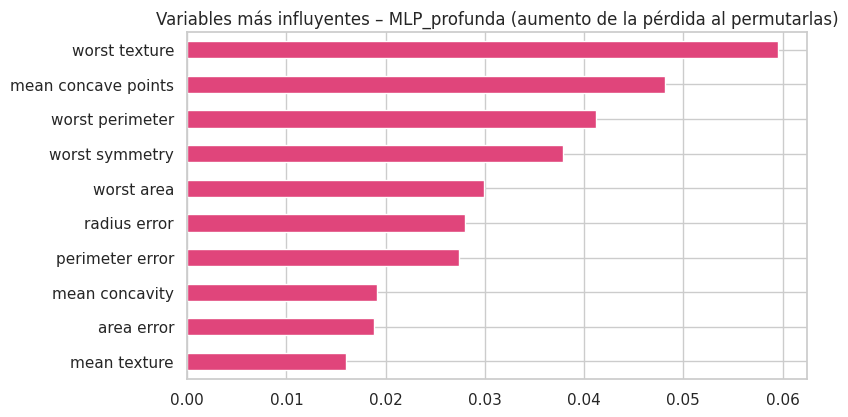

In [17]:
# Modelo recomendado: se elige con la VALIDACIÓN (no con la prueba): mayor F1, luego ROC-AUC y menor pérdida
puntaje = {n: (evaluar(yva, prob[n]["val"])["f1"], evaluar(yva, prob[n]["val"])["roc_auc"], -evaluar(yva, prob[n]["val"])["loss"]) for n in modelos}
recomendado = max(puntaje, key=puntaje.get)
print("Modelo recomendado según la validación:", recomendado)

# Casos mal clasificados en prueba, consultados en SQL
for n in modelos:
    pred = (prob[n]["test"] >= 0.5).astype(int)
    err = id_te[pred != yte]
    if len(err):
        print(f"\n{n}: {len(err)} error(es) en prueba")
        display(pd.read_sql(f"SELECT id, diagnostico, ROUND(mean_radius, 2) AS radio, ROUND(mean_concavity, 3) AS concavidad, ROUND(worst_texture, 1) AS textura_peor FROM pacientes WHERE id IN ({', '.join(map(str, err))})", con))
    else:
        print(f"\n{n}: sin errores en prueba (con umbral 0,5)")

def importancia_permutacion(modelo, X, y, n_rep=5, seed=0):
    rng = np.random.default_rng(seed); base = evaluar(y, dl.predecir(modelo, X))["loss"]; out = []
    for j in range(X.shape[1]):
        aumentos = []
        for _ in range(n_rep):
            Xp = X.copy(); Xp[:, j] = rng.permutation(Xp[:, j]); aumentos.append(evaluar(y, dl.predecir(modelo, Xp))["loss"] - base)
        out.append(np.mean(aumentos))
    return np.array(out)
imp = importancia_permutacion(modelos[recomendado], np.vstack([Zva, Zte]), np.concatenate([yva, yte]))
top = pd.Series(imp, index=dl.FEATURES).sort_values(ascending=False).head(10)
top.sort_values().plot(kind="barh", color="#e0457b", figsize=(8, 4.5), title=f"Variables más influyentes – {recomendado} (aumento de la pérdida al permutarlas)"); plt.show()

> **Referencia:** en el ACA 1 de esta asignatura, un SVM clásico alcanzó una exactitud de 97,37 % y un recall de 92,86 % con otra partición (80/20). Las cifras **no son directamente comparables** porque aquí la partición y el tamaño de la prueba son distintos; sirven como orden de magnitud de lo que ya se lograba con modelos clásicos en este dataset.

## 5. Paso 5 – Exportación para Streamlit
Se guardan los dos modelos entrenados, los parámetros de estandarización, las métricas (con curvas, matrices de confusión y ROC) y la base SQL. La app los carga sin volver a entrenar.

In [18]:
from datetime import datetime
ahora = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
for n in modelos:
    for sp in ("val", "test"):
        m = evaluar(yva if sp == "val" else yte, prob[n][sp])
        cur.execute("INSERT INTO experimentos (fecha, modelo, particion, umbral, accuracy, precision_, recall, f1, roc_auc, loss, parametros) VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                    (ahora, n, sp, 0.5, m["accuracy"], m["precision"], m["recall"], m["f1"], m["roc_auc"], m["loss"], int(modelos[n].count_params())))
con.commit()
display(pd.read_sql("SELECT modelo, particion, ROUND(accuracy, 4) AS accuracy, ROUND(recall, 4) AS recall, ROUND(f1, 4) AS f1, parametros FROM experimentos", con))

OUT = Path("artefactos_streamlit"); shutil.rmtree(OUT, ignore_errors=True); OUT.mkdir()
metricas = {"features": dl.FEATURES, "recomendado": recomendado, "semilla": SEMILLA, "n_semillas": N_SEMILLAS, "keras": keras.__version__,
            "particion": {"train": int(len(ytr)), "val": int(len(yva)), "test": int(len(yte))}, "modelos": {}}
for n, m in modelos.items():
    fpr, tpr, _ = roc_curve(yte, prob[n]["test"]); paso = max(1, len(fpr) // 60)
    d_sem = pd.DataFrame(repeticiones[n])
    metricas["modelos"][n] = {"parametros": int(m.count_params()), "epocas": len(historiales[n]["loss"]), "tiempo_s": round(tiempos[n], 1),
        "historial": historiales[n], "val": evaluar(yva, prob[n]["val"]), "test": evaluar(yte, prob[n]["test"]),
        "umbral_ajustado": umbrales[n], "test_umbral_ajustado": evaluar(yte, prob[n]["test"], umbrales[n]),
        "roc": {"fpr": [float(x) for x in fpr[::paso]], "tpr": [float(x) for x in tpr[::paso]]},
        "semillas": {k: [float(d_sem[k].mean()), float(d_sem[k].std())] for k in ("accuracy", "precision", "recall", "f1", "roc_auc")}}
metricas["importancia_variables"] = {k: float(v) for k, v in top.items()}
with open(OUT / "metricas.json", "w") as f: json.dump(metricas, f)
with open(OUT / "escalador.json", "w") as f: json.dump({"features": dl.FEATURES, "media": [float(x) for x in media], "desv": [float(x) for x in desv]}, f)
for n, m in modelos.items(): m.save(OUT / f"{n}.keras")
con.commit(); con.close(); shutil.copy(DB, OUT / DB)
with zipfile.ZipFile("artefactos_streamlit.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.iterdir(): z.write(p, p.name)
print("Artefactos generados:", sorted(p.name for p in OUT.iterdir()))
try:
    from google.colab import files
    files.download("artefactos_streamlit.zip")
except Exception:
    print("Descarga manual: artefactos_streamlit.zip (panel de archivos)")

,modelo,particion,accuracy,recall,f1,parametros
0,MLP_profunda,val,0.9765,0.9688,0.9688,15233
1,MLP_profunda,test,1.0000,1.0000,1.0000,15233
2,FT_Transformer,val,0.9647,0.9375,0.9524,20193
3,FT_Transformer,test,0.9884,1.0000,0.9846,20193


Artefactos generados: ['FT_Transformer.keras', 'MLP_profunda.keras', 'escalador.json', 'metricas.json', 'wdbc.db']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Interfaz Streamlit
La app (`app.py`, en el repositorio) carga los modelos exportados y tiene cuatro pestañas:

| Pestaña | Contenido |
|---|---|
| **Predicción** | 30 variables con deslizadores (rangos tomados de la base SQL), ejemplos benigno/maligno desde la base, predicción de **ambas redes**, umbral ajustable, acuerdo entre modelos y registro de la predicción en SQL |
| **Datos (SQL)** | Resumen del dataset, explorador con filtros, consola SQL de solo lectura con consultas de ejemplo e historial de predicciones |
| **Modelos** | Arquitecturas, tablas de métricas, matrices de confusión, curvas de aprendizaje y ROC, estabilidad con semillas e importancia de variables |
| **Acerca** | Metodología, limitaciones y aviso médico |

Instrucciones de ejecución: ver el `README.md` del repositorio.

## 7. Análisis y conclusiones
El desarrollo del proyecto permitió explorar la aplicación de redes neuronales profundas en la clasificación de tumores de mama, comparando las arquitecturas MLP y FT-Transformer. Se implementó un proceso integral que incluyó la exploración y preparación de datos, almacenamiento mediante SQL, entrenamiento, evaluación de modelos y despliegue mediante Streamlit. Asimismo, se evidenció la importancia de utilizar métricas como el recall, la precisión y el F1-score, especialmente en contextos médicos donde la identificación de casos malignos resulta prioritaria. El proyecto también permitió integrar diferentes herramientas y técnicas para construir una solución de inteligencia artificial aplicada al sector salud.


Las redes neuronales profundas ofrecen herramientas para identificar patrones en datos médicos y apoyar procesos de clasificación.

La comparación entre MLP y FT-Transformer permite explorar diferentes arquitecturas para el tratamiento de datos estructurados.

La integración de SQL y Streamlit facilita la gestión de información y la utilización práctica de los modelos desarrollados.

Es importante realizar pruebas adicionales con conjuntos de datos más amplios y validaciones externas para fortalecer la confiabilidad de los resultados.

## Referencias (APA 7)
Chollet, F. (2015). *Keras*. https://keras.io

Gorishniy, Y., Rubachev, I., Khrulkov, V., & Babenko, A. (2021). Revisiting deep learning models for tabular data. *Advances in Neural Information Processing Systems, 34*, 18932–18943. https://arxiv.org/abs/2106.11959

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*, 5998–6008. https://arxiv.org/abs/1706.03762

Wolberg, W., Street, N., & Mangasarian, O. (1995). *UCI Breast Cancer Wisconsin (Diagnostic)* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic